# Discovery evidence and robustness

I validate the discovery hypothesis with landing/exit pages, user-clustered intervals, paired user bootstrap uncertainty, an observational proxy-to-revenue scenario, tracking alerts, activation calibration and definition sensitivity.

Run `python scripts/evidence.py` first. The script reads the database without changing it. [Methods and limits](docs/evidence_review.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, 'scripts')
import analysis as a
a.chart_style()
folder = Path('docs/evidence')
def load(name):
    return pd.read_csv(folder / f'{name}.csv')

## Observed landing and exit pages

I retain sessions without page views. Page titles are not unique URLs, and product-titled pages without product-view events make tracking validation a prerequisite for the experiment.

In [2]:
display(load('landing_pages').head(15))
display(load('nonviewer_exit_pages').head(15))

,landing_page,sessions,product_view_rate,order_session_rate,share_of_sessions
0,Home,68567,0.242128,0.024297,0.275736
1,Google Online Store,41079,0.123323,0.005696,0.165196
2,Apparel | Google Merchandise Store,33585,0.075123,0.002382,0.135059
3,Google Dino Game Tee,16797,0.074894,0.000060,0.067548
4,[No page_view],16494,0.013217,0.000000,0.066329
5,YouTube | Shop by Brand | Google Merchandise S...,16452,0.194566,0.002067,0.066160
6,Men's T-Shirts | Apparel | Google Merchandise ...,4636,0.357420,0.006687,0.018643
7,Page Unavailable,3757,0.053766,0.000000,0.015108
8,Drinkware | Lifestyle | Google Merchandise Store,3099,0.107777,0.010003,0.012462
9,Shopping Cart,2642,0.361090,0.100681,0.010625


,exit_page,sessions,share_of_nonview_sessions
0,Home,44406,0.223805
1,Apparel | Google Merchandise Store,30630,0.154374
2,Google Online Store,28687,0.144582
3,[No page_view],16276,0.082031
4,Google Dino Game Tee,15335,0.077288
5,YouTube | Shop by Brand | Google Merchandise S...,11837,0.059658
6,Store search results,3783,0.019066
7,Drinkware | Lifestyle | Google Merchandise Store,3470,0.017489
8,Page Unavailable,3376,0.017015
9,Men's / Unisex | Apparel | Google Merchandise ...,3178,0.016017


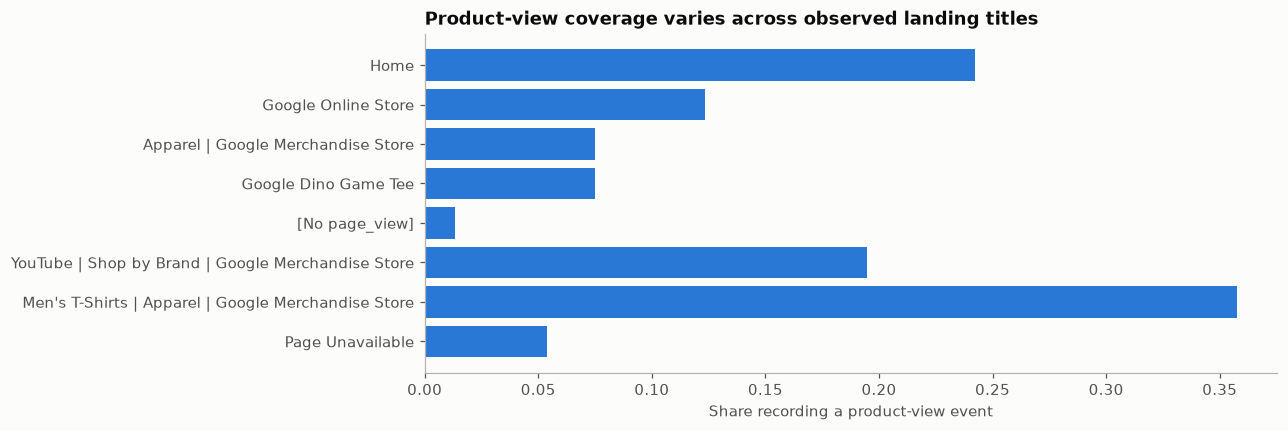

In [3]:
landing = load('landing_pages').head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(landing.landing_page, landing.product_view_rate, color=a.BLUE)
ax.set_xlabel('Share recording a product-view event')
ax.set_title('Product-view coverage varies across observed landing titles')
fig.savefig('charts/landing_pages.png')
plt.show()

## Market comparison: user-clustered difference intervals

In [4]:
display(load('market_comparison'))

,step_order,step,India_rate,India_moe,India_entering,United States_rate,United States_moe,United States_entering,gap,gap_ci_low,gap_ci_high,verdict
0,2,View item,0.203767,0.005938,23306,0.202579,0.002747,109093,0.001188,-0.005355,0.007730,No clear difference
1,3,Add to cart,0.265740,0.013830,4749,0.273303,0.006616,22100,-0.007563,-0.022894,0.007768,No clear difference
2,4,Begin checkout,0.498415,0.034904,1262,0.506788,0.016268,6040,-0.008373,-0.046882,0.030136,No clear difference
3,5,Add payment info,0.661367,0.039065,629,0.656648,0.017483,3061,0.004719,-0.038080,0.047518,No clear difference
4,6,Order,0.706731,0.044965,416,0.693532,0.021027,2010,0.013198,-0.036440,0.062837,No clear difference
5,7,Session conversion,0.012615,0.001522,23306,0.012778,0.000702,109093,-0.000163,-0.001839,0.001513,No clear difference


## Revenue scenarios: paired whole-user bootstrap

I keep sampling intervals separate from the original low/base/high business assumptions. These intervals cannot establish the effect of an intervention.

In [5]:
display(load('revenue_bootstrap'))
display(json.loads((folder / 'revenue_bootstrap.json').read_text()))

,step,usd_base,ci_low,ci_high
0,View item,5965.685758,5640.622222,6295.127689
1,Add to cart,4443.347582,4191.680494,4693.005779
2,Begin checkout,2370.259581,2242.657914,2498.338573
3,Add payment info,1821.063994,1722.583406,1916.683372
4,Order,1732.260137,1638.062224,1822.711964


{'repetitions': 1000,
 'seed': 42,
 'users': 193296,
 'view_minus_cart_ci_low': 1401.4494317588824,
 'view_minus_cart_ci_high': 1648.9991970214694,
 'bootstrap_share_view_exceeds_cart': 1.0,
 'scope': 'Sampling uncertainty conditional on the +1-point scenario; not causal uncertainty.'}

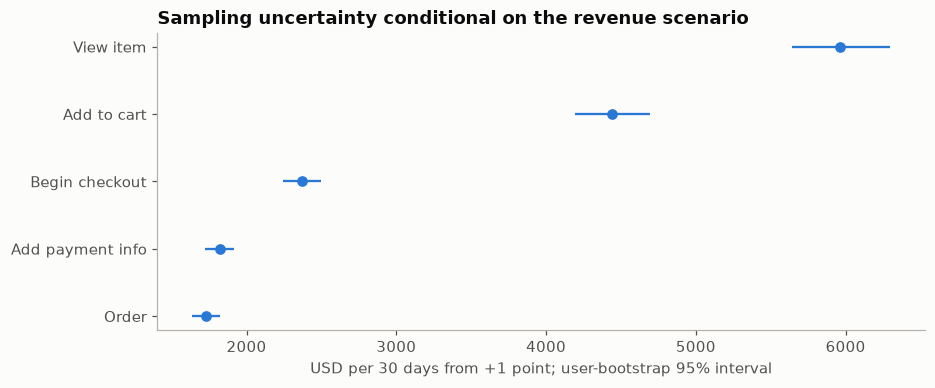

In [6]:
ras = load('revenue_bootstrap').iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(ras.usd_base, ras.step, xerr=[ras.usd_base-ras.ci_low, ras.ci_high-ras.usd_base], fmt='o', color=a.BLUE)
ax.set_xlabel('USD per 30 days from +1 point; user-bootstrap 95% interval')
ax.set_title('Sampling uncertainty conditional on the revenue scenario')
fig.savefig('charts/revenue_bootstrap.png')
plt.show()

## Product views and subsequent revenue

These are adjusted associations among historical first-session non-buyers. The projection assumes those associations transfer to marginal viewers and holds the exposure lift fixed. It is not a causal prediction, a monthly forecast, or an estimate for all experiment entrants.

In [7]:
display(load('proxy_raw'))
display(load('proxy_adjusted'))

,viewed,users,buyers,purchase_rate,revenue_per_user
0,0,79617,242,0.003040,0.267242
1,1,18936,523,0.027619,2.445659


,outcome,adjusted_difference,ci_low,ci_high,additional_viewers_at_5pct_lift,projected_change,projected_ci_low,projected_ci_high
0,bought,0.024412,0.022048,0.026776,946.8,23.113130,20.874919,25.351342
1,revenue_30d,2.160759,1.827942,2.493576,946.8,2045.806665,1730.695208,2360.918122


## Retrospective tracking audit

Count alerts use six neighbouring days. Valid-purchase coverage below 80% of its full-period median raises a separate coverage warning. Zero-volume days remain flagged even in a sustained outage. Future-day references mean this is not an online monitor.

In [8]:
display(load('tracking_alerts'))

,date,metric,observed,neighbour_median,ratio,alert
0,2020-11-02,add_to_cart,0.000000,0.000000,NaN,zero_volume
1,2020-11-03,add_to_cart,0.000000,0.000000,NaN,zero_volume
2,2020-11-04,add_to_cart,0.000000,0.000000,NaN,zero_volume
3,2020-11-05,add_to_cart,0.000000,0.000000,NaN,zero_volume
4,2020-11-06,add_to_cart,0.000000,0.000000,NaN,zero_volume
5,2020-11-07,add_to_cart,0.000000,0.000000,NaN,zero_volume
6,2020-11-08,add_to_cart,0.000000,0.000000,NaN,zero_volume
7,2020-11-09,add_to_cart,0.000000,0.000000,NaN,zero_volume
8,2020-11-10,add_to_cart,0.000000,0.000000,NaN,zero_volume
9,2020-11-11,add_to_cart,0.000000,0.000000,NaN,zero_volume


## Activation calibration and definition sensitivity

In [9]:
display(load('activation_calibration'))
display(json.loads((folder / 'activation_diagnostics.json').read_text()))
display(load('definition_sensitivity'))

,decile,users,buyers,predicted,actual
0,1,4911,8,0.000566,0.001629
1,2,4910,5,0.000668,0.001018
2,3,4910,3,0.001137,0.000611
3,4,4911,1,0.001620,0.000204
4,5,4910,1,0.002120,0.000204
5,6,4910,5,0.002827,0.001018
6,7,4911,11,0.004018,0.002240
7,8,4910,22,0.006290,0.004481
8,9,4910,60,0.011961,0.012220
9,10,4911,196,0.043813,0.039910


{'model_auc': 0.869208999688894,
 'cart_rule_auc': 0.6546107810864328,
 'brier_score': 0.006095647614135957,
 'top_decile_precision': 0.03991040521278762,
 'top_decile_recall': 0.6282051282051282}

,definition,sessions,orders,revenue_usd,session_conversion,product_view_rate
0,Baseline,248669.0,3540.0,245147.0,0.012852,0.202096
1,Require session_start,245677.0,3504.0,241026.0,0.012866,0.201158
2,Start 25 November,253273.0,3635.0,252794.0,0.012943,0.203117
3,Order key: user + transaction,248669.0,3555.0,246337.0,0.012897,0.202096
